# Jy OCR evaluation — fresh original crops and full-photo preview

This notebook compares **existing trained readers** on the reviewed Jy originals. It does not train models. By default it opens saved predictions, so you can revise the results without loading PaddleOCR.

There are **298 originals**, not 2,384 independent test examples. The other files are seven synthetic variants per original. The supplied `train`/`test` names are ignored because variants of the same handwriting appear in both folders; all originals remain evaluation data for our already-trained readers.

Labels were reported reviewed by a teammate on 8 November 2026. Writer provenance is user supplied. Full-photo boxes/completeness are a separate review: crop scores do not measure missed detections or all text on a board.

In [1]:
from pathlib import Path
import json, html, difflib, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display, HTML, Markdown

ASSIGNMENT_OVERRIDE = None  # set an absolute path only if automatic discovery fails
roots = [Path(ASSIGNMENT_OVERRIDE)] if ASSIGNMENT_OVERRIDE else []
for p in [Path.cwd(), *Path.cwd().parents]:
    roots.extend([p, p / 'Assignment'])
ASSIGNMENT = next((p.resolve() for p in roots if (p / 'Jy Dataset/labels_augmented.txt').is_file()), None)
if ASSIGNMENT is None:
    raise FileNotFoundError('Set ASSIGNMENT_OVERRIDE to your Assignment folder.')
PROJECT = ASSIGNMENT / 'whiteboard-ocr'
OUT = PROJECT / 'outputs/jy_ocr_evaluation'
DATASET = ASSIGNMENT / 'Jy Dataset'
RUNNER = PROJECT / 'scripts/evaluate_jy_readers.py'
PYTHON = ASSIGNMENT / '.venv-paddle/bin/python'
print('Assignment:', ASSIGNMENT)
print('Saved results:', OUT)


Assignment: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment
Saved results: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment/whiteboard-ocr/outputs/jy_ocr_evaluation


## 1. Run controls

Leave `RUN_EVALUATION=False` to inspect completed results. Turning it on runs **inference only**, with each model in a separate process. The first run may take several minutes on a laptop; verified cached results are reused.

Default models: matched seeds for S0, S1 and G0. Do not choose a favourable seed from this evaluation. A smoke run writes to its own `smoke_N` folder and does not support a formal decision.

In [2]:
RUN_EVALUATION = False
RUN_LIMIT = 0  # 0 = all 298 originals; 3 = small end-to-end smoke test
MODELS = ['S0', 'S0s2', 'S1', 'S1s2', 'G0', 'G0s2']
CPU_THREADS = 4

if RUN_EVALUATION:
    command = [str(PYTHON), str(RUNNER), '--models', ','.join(MODELS),
               '--limit', str(RUN_LIMIT), '--threads', str(CPU_THREADS)]
    subprocess.run(command, check=True, cwd=ASSIGNMENT)
VIEW_OUT = OUT / f'smoke_{RUN_LIMIT}' if RUN_LIMIT else OUT
prediction_file = VIEW_OUT / 'predictions.csv'
df = pd.read_csv(prediction_file, keep_default_na=False) if prediction_file.exists() else None
saved = json.loads((VIEW_OUT / 'summary.json').read_text()) if (VIEW_OUT / 'summary.json').exists() else None
if df is None:
    display(Markdown('**No saved predictions yet.** Run the inference cell above, or return after the evaluation finishes.'))
else:
    assert not df.duplicated(['model', 'file']).any()
    print(f'{len(df):,} prediction rows; {df.file.nunique()} distinct crops; models: {list(df.model.unique())}')
    if df.file.nunique() != 298:
        display(Markdown('**Partial/smoke result: do not present this as the complete Jy evaluation.**'))


1,788 prediction rows; 298 distinct crops; models: ['S0', 'S0s2', 'S1', 'S1s2', 'G0', 'G0s2']


## 2. What did each reader get right?

**CER** counts character edits: lower is better. Mean line CER gives each crop equal weight, while corpus CER gives each reference character equal weight. Exact-line accuracy asks whether the entire original-case string is correct.

A blank reading is also an error. Model startup/image decoding are excluded from backend inference seconds; these are not full application latency measurements. Other OCR work could run on the computer during this collection, so these timings are indicative and **must not be used as controlled speed benchmarks**.

,crops,mean line CER (%),corpus CER (%),exact lines (%),blank_readings,inference_seconds
S0,298.0,7.35,6.36,52.01,0.0,69.64
S0s2,298.0,7.33,6.44,52.35,0.0,79.18
S1,298.0,5.57,5.08,56.71,0.0,88.18
S1s2,298.0,5.48,5.08,59.73,0.0,86.40
G0,298.0,5.91,5.46,56.71,0.0,130.42
G0s2,298.0,5.38,4.67,62.08,0.0,70.07


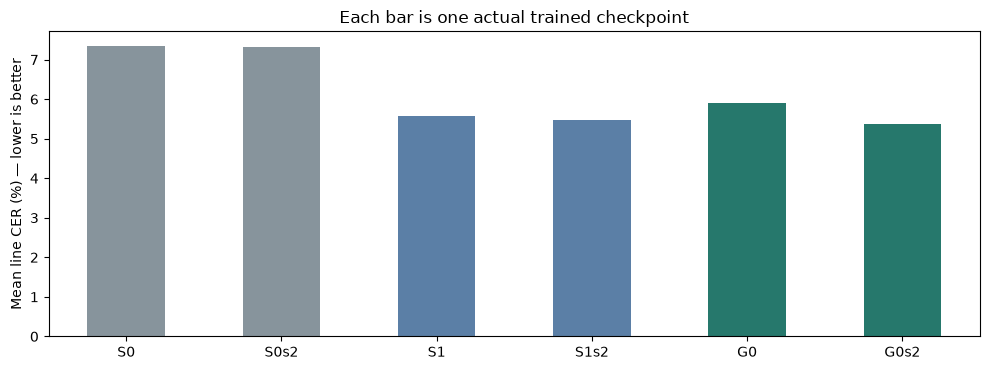

In [3]:
summary_table = None
if saved:
    summary_table = pd.DataFrame(saved['models']).T
    summary_table['mean line CER (%)'] = 100 * summary_table['mean_line_CER']
    summary_table['corpus CER (%)'] = 100 * summary_table['corpus_CER']
    summary_table['exact lines (%)'] = 100 * summary_table['exact_case']
    display(summary_table[['crops', 'mean line CER (%)', 'corpus CER (%)', 'exact lines (%)', 'blank_readings', 'inference_seconds']].round(2))
    fig, ax = plt.subplots(figsize=(10, 3.8))
    summary_table['mean line CER (%)'].plot.bar(ax=ax, color=['#87949c' if m.startswith('S0') else '#5b7fa6' if m.startswith('S1') else '#26786c' for m in summary_table.index])
    ax.set_ylabel('Mean line CER (%) — lower is better'); ax.set_xlabel('')
    ax.set_title('Each bar is one actual trained checkpoint'); ax.set_ylim(bottom=0)
    plt.xticks(rotation=0); plt.tight_layout(); plt.show()


## 3. Did the change repeat across two seeds?

The **primary fresh-collection confirmation** is G0 versus S0, fixed in `protocol.json` before inference. It is separate from the earlier whiteboard-validation study and does not rewrite that study's inconclusive result.

A gain qualifies under this rule only if both matched seeds improve and the photo-cluster interval for their average is below zero. S1 is a secondary comparison. Intervals hold these trained seeds fixed; they do not establish performance across all writers.

,comparison,role,seed 1 change (pp),seed 2 change (pp),average change (pp),95% interval (pp),decision
0,G0 vs S0,primary confirmation,-1.44,-1.95,-1.70,-3.02 .. -0.33,helps
1,S1 vs S0,secondary,-1.78,-1.85,-1.82,-3.01 .. -0.98,helps


**Negative change means fewer errors.** The average of two seeds is a statistic, not a model that the app can load.

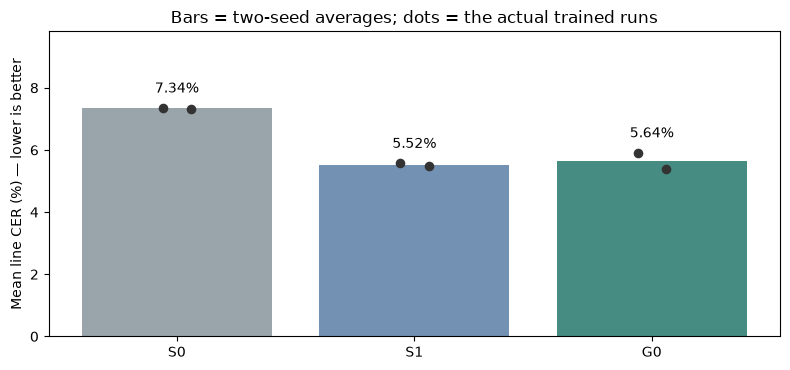

In [4]:
if saved:
    comparison_rows = []
    for name, c in saved.get('comparisons', {}).items():
        q = c['mean']
        comparison_rows.append({'comparison': name, 'role': c['role'],
            'seed 1 change (pp)': 100*c['seed1']['difference'],
            'seed 2 change (pp)': 100*c['seed2']['difference'],
            'average change (pp)': 100*q['difference'],
            '95% interval (pp)': f"{100*q['low']:+.2f} .. {100*q['high']:+.2f}",
            'decision': c['decision']})
    display(pd.DataFrame(comparison_rows).round(2)) if comparison_rows else display(Markdown('Both seed pairs are needed before this table can be calculated.'))
    display(Markdown('**Negative change means fewer errors.** The average of two seeds is a statistic, not a model that the app can load.'))
    if df is not None and all(m in set(df.model) for m in ['S0','S0s2','S1','S1s2','G0','G0s2']):
        per_model = df.groupby('model').cer.mean() * 100
        bases = ['S0', 'S1', 'G0']
        means = [(per_model[b] + per_model[b+'s2']) / 2 for b in bases]
        fig, ax = plt.subplots(figsize=(8, 3.8))
        ax.bar(bases, means, color=['#87949c','#5b7fa6','#26786c'], alpha=.85)
        for i, b in enumerate(bases):
            ax.scatter([i-.06,i+.06], [per_model[b],per_model[b+'s2']], color='#333333', zorder=3, s=35)
            ax.text(i, max(per_model[b],per_model[b+'s2']) + .5, f'{means[i]:.2f}%', ha='center')
        ax.set_ylabel('Mean line CER (%) — lower is better')
        ax.set_title('Bars = two-seed averages; dots = the actual trained runs')
        ax.set_ylim(0, max(per_model[m] for m in ['S0','S0s2','S1','S1s2','G0','G0s2']) * 1.2 + 1)
        plt.tight_layout(); plt.show()


## 4. Words and sentences are different difficulties

Jy contains **241 single-word crops** and **57 multi-word crops**; only 13 labels exceed 40 characters. A large overall gain could therefore be driven mostly by short words. Read the groups below before claiming longer sentences improved.

In [5]:
if df is not None:
    for field, title in [('word_group', 'One word versus multiple words'), ('length_group', 'Label length'), ('photo', 'Source photo')]:
        table = df.groupby(['model', field]).cer.mean().unstack() * 100
        display(Markdown(f'**{title}: mean line CER (%)**'))
        display(table.round(2))


**One word versus multiple words: mean line CER (%)**

word_group,multiple words,one word
model,,
G0,5.43,6.02
G0s2,4.19,5.66
S0,5.31,7.83
S0s2,5.38,7.79
S1,4.41,5.84
S1s2,4.55,5.70


**Label length: mean line CER (%)**

length_group,1-20,21-40,>40
model,,,
G0,5.91,6.64,3.78
G0s2,5.56,4.68,3.74
S0,7.75,5.30,5.40
S0s2,7.67,5.81,5.04
S1,5.76,4.61,4.56
S1s2,5.60,5.16,4.01


**Source photo: mean line CER (%)**

photo,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
model,,,,,,,,,,,,,,,,
G0,3.30,8.34,4.18,2.84,6.72,8.27,5.14,4.67,9.35,9.72,5.53,8.53,9.25,6.37,5.12,1.87
G0s2,4.91,3.85,4.78,2.61,6.93,6.68,1.87,5.19,9.07,12.20,4.06,9.22,8.27,4.53,4.09,0.65
S0,7.88,6.72,7.25,3.20,7.74,10.19,6.37,6.12,9.23,22.32,5.61,11.93,5.62,5.52,3.96,1.01
S0s2,6.34,6.96,5.73,4.49,9.14,10.19,5.00,4.61,8.23,18.90,6.43,17.05,5.48,6.05,5.50,0.65
S1,5.53,5.48,5.60,3.30,5.31,6.68,5.05,4.06,7.75,12.20,4.96,9.59,5.37,4.87,3.88,0.65
S1s2,5.51,6.69,5.84,2.04,5.73,6.68,5.17,4.63,6.29,12.50,3.40,8.44,3.56,7.22,4.73,1.47


## 5. Look at the actual handwriting and predictions

The image and correct label stay the same for all readers. Colours only help locate text differences; the reported CER comes from Levenshtein edits, not this display's string matcher.

Use `show_crop(index=..., models=[...])` directly, or the dropdown if widgets are available.

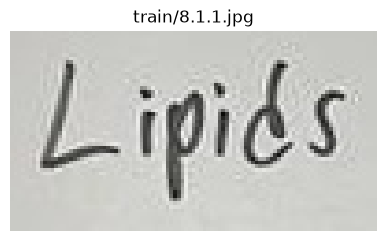

Model,Prediction (differences highlighted),CER
S0,LipidsNormalised differences: lipids,0.0%
S0s2,LipidsNormalised differences: lipids,0.0%
S1,LipidsNormalised differences: lipids,0.0%
S1s2,LipidsNormalised differences: lipids,0.0%
G0,LipidsNormalised differences: lipids,0.0%
G0s2,LipidsNormalised differences: lipids,0.0%


Output()

Dropdown(description='Crop:', layout=Layout(width='95%'), options=(('train/8.1.1.jpg: Lipids', 'train/8.1.1.jp…

In [6]:
def highlight(label, pred):
    target = ' '.join(label.lower().split())
    guess = ' '.join(pred.lower().split())
    pieces = []
    for tag, i, j, k, l in difflib.SequenceMatcher(None, target, guess, autojunk=False).get_opcodes():
        if tag == 'equal':
            pieces.append(html.escape(guess[k:l]))
        elif tag == 'delete':
            pieces.append('<span style="background:#ffe4e4;color:#9c2222;text-decoration:line-through">' + html.escape(target[i:j]) + '</span>')
        else:
            pieces.append('<span style="background:#ffe7ae;color:#754500">' + html.escape(guess[k:l]) + '</span>')
    return ''.join(pieces) or '<i>[empty reading]</i>'

def show_crop(index=0, models=None, file=None):
    if df is None:
        print('Run/load predictions first.'); return
    files = list(dict.fromkeys(df.file))
    name = file or files[min(max(0, int(index)), len(files)-1)]
    rows = df[df.file.eq(name)]
    if models:
        rows = rows[rows.model.isin(models)]
    with Image.open(DATASET / name) as im:
        image = ImageOps.exif_transpose(im).convert('RGB')
        fig, ax = plt.subplots(figsize=(13, 2.6))
        ax.imshow(image); ax.axis('off'); ax.set_title(name); plt.show()
    label = rows.iloc[0].label
    body = '<p><b>Reviewed ground truth:</b> ' + html.escape(label) + '</p>'
    body += '<table><tr><th style="padding:8px">Model</th><th>Prediction (differences highlighted)</th><th style="padding:8px">CER</th></tr>'
    for r in rows.itertuples():
        raw = html.escape(r.pred) if r.pred else '<i>[empty reading]</i>'
        body += f'<tr><td style="padding:8px">{html.escape(r.model)}</td><td style="font-family:monospace"><div>{raw}</div><small>Normalised differences: {highlight(label, r.pred)}</small></td><td style="padding:8px">{r.cer:.1%}</td></tr>'
    display(HTML(body + '</table>'))

if df is not None:
    show_crop(0)
    try:
        import ipywidgets as widgets
        options = [(f"{r.file}: {r.label}", r.file) for r in df.drop_duplicates('file').itertuples()]
        chooser = widgets.Dropdown(options=options, description='Crop:', layout=widgets.Layout(width='95%'))
        display(widgets.interactive_output(lambda file: show_crop(file=file), {'file': chooser}))
        display(chooser)
    except ImportError:
        print('Widgets unavailable; call show_crop(index=10) manually.')


## 6. Improvements AND regressions

The examples below are deliberately selected to illustrate the largest seed-averaged changes. They are not a random sample. Both seed readings are shown so that one lucky reading does not conceal the other.

**Largest improvements (negative change):**

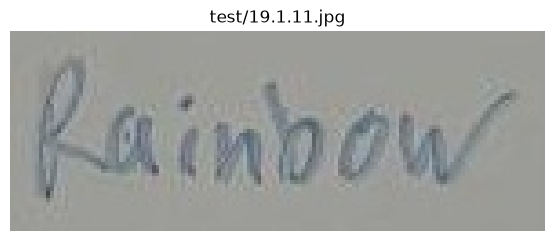

Model,Prediction (differences highlighted),CER
S0,R.an inboowNormalised differences: r.an inboow,57.1%
S0s2,Re cen ionioowNormalised differences: re cen ionioow,128.6%
G0,BaninloowNormalised differences: baninloow,57.1%
G0s2,RainloowNormalised differences: rainloow,28.6%


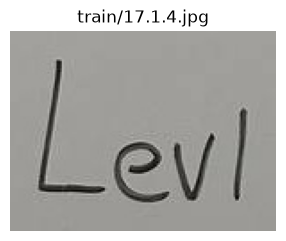

Model,Prediction (differences highlighted),CER
S0,Leu1Normalised differences: leu1,50.0%
S0s2,LeV1Normalised differences: lev1,25.0%
G0,LevlNormalised differences: levl,0.0%
G0s2,LevlNormalised differences: levl,0.0%


**Largest regressions (positive change):**

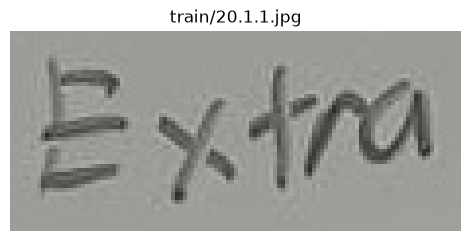

Model,Prediction (differences highlighted),CER
S0,ExtraNormalised differences: extra,0.0%
S0s2,ExtraNormalised differences: extra,0.0%
G0,=xtraNormalised differences: =xtra,20.0%
G0s2,xtnaNormalised differences: extna,40.0%


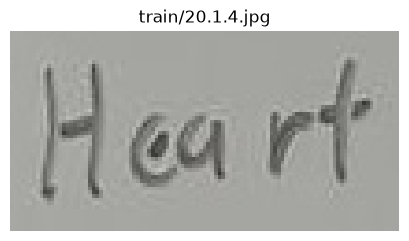

Model,Prediction (differences highlighted),CER
S0,Hea rtNormalised differences: hea rt,20.0%
S0s2,Hea rtNormalised differences: hea rt,20.0%
G0,Hea vtNormalised differences: hea vt,40.0%
G0s2,Hea vdNormalised differences: hea vd,60.0%


In [7]:
if df is not None and all(m in set(df.model) for m in ['S0','S0s2','G0','G0s2']):
    compared = df[df.model.isin(['S0','S0s2','G0','G0s2'])].pivot(index='file', columns='model', values='cer')
    compared['change'] = (compared.G0 + compared.G0s2 - compared.S0 - compared.S0s2) / 2
    display(Markdown('**Largest improvements (negative change):**'))
    for name in compared.nsmallest(2, 'change').index:
        show_crop(file=name, models=['S0','S0s2','G0','G0s2'])
    display(Markdown('**Largest regressions (positive change):**'))
    for name in compared.nlargest(2, 'change').index:
        show_crop(file=name, models=['S0','S0s2','G0','G0s2'])


## 7. Optional live full-photo preview

This runs the detector plus the selected reader on one whole photograph. It shows **what the prototype actually reads**, but does not invent full-photo CER. Ground-truth positions/order/completeness need separate review; Photo 14 contains faint text not present in its crop labels.

Leave the switch off to avoid loading OCR models while studying saved results. No learned super-resolution or VLM is involved.

Saved full-photo output: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment/whiteboard-ocr/outputs/jy_ocr_evaluation/full_photos/G0s2/Photo_23.json


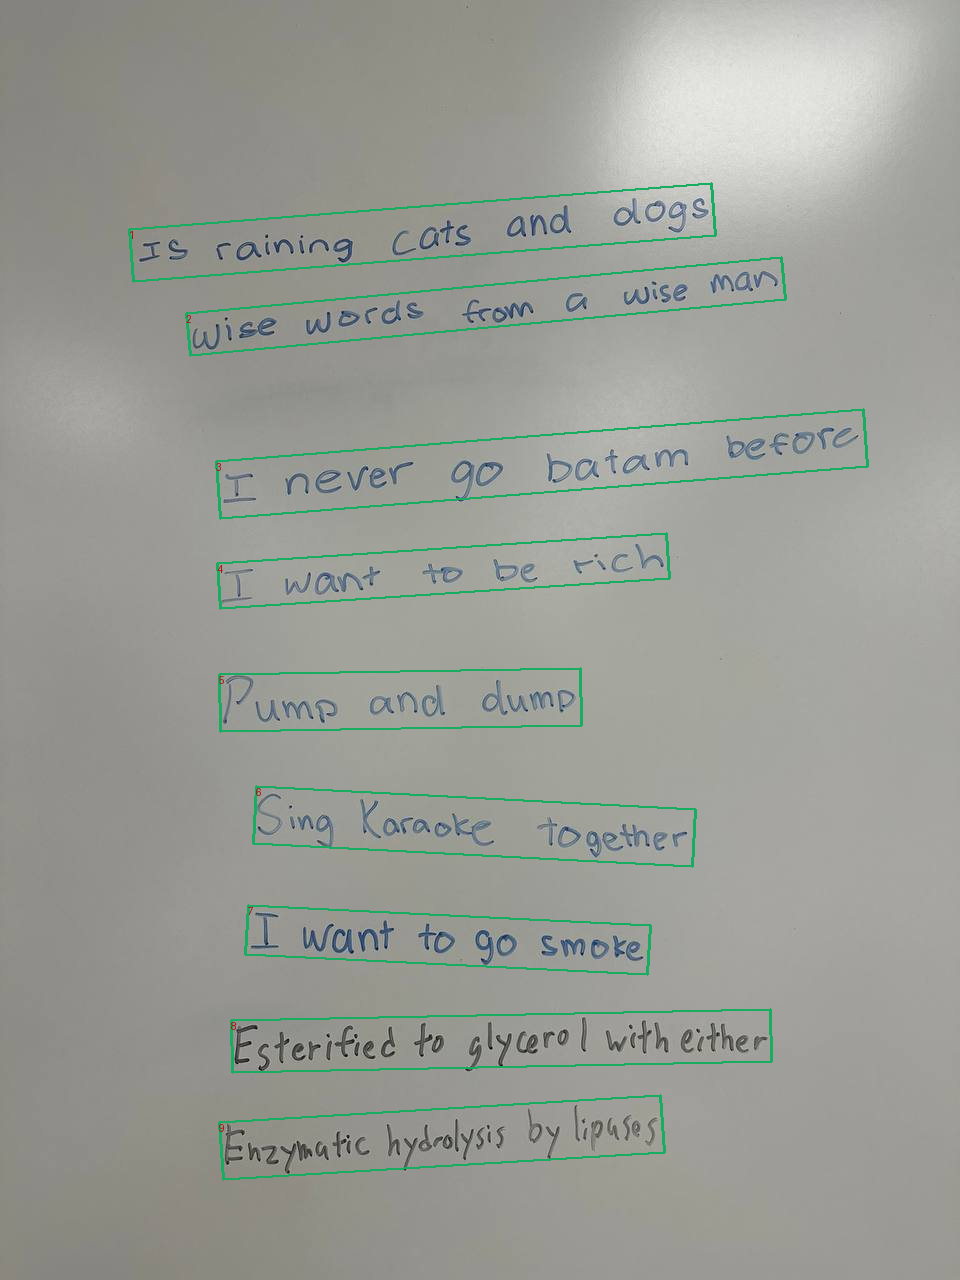

IS raining cats and dogs
wise words from a wise man
I never go batam before
I want to oe ich
Pump and dump
Sing Karaoke together
I want to go smoke
Esterified to glycerol with either
Enzymatic hydrolysis by lipases
Processing seconds (not a controlled speed benchmark): 15.45


,text,score
0,IS raining cats and dogs,0.968524
1,wise words from a wise man,0.961389
2,I never go batam before,0.977949
3,I want to oe ich,0.935511
4,Pump and dump,0.998536
5,Sing Karaoke together,0.997458
6,I want to go smoke,0.979711
7,Esterified to glycerol with either,0.996460
8,Enzymatic hydrolysis by lipases,0.969507


**OCR output, not verified full-photo accuracy.** Inspect missed/extra text and column order.

In [8]:
RUN_PHOTO_DEMO = False
PHOTO_NAME = 'Photo 23.jpg'
PHOTO_MODEL = 'G0s2'
result = None
if RUN_PHOTO_DEMO:
    sys.path.insert(0, str(PROJECT / 'ocr_prototype'))
    from ocr_backend import OCRService
    service = OCRService(model_id=PHOTO_MODEL)
    result = service.recognise(DATASET / PHOTO_NAME)
else:
    candidates = [OUT / 'full_photos' / PHOTO_MODEL / (Path(PHOTO_NAME).stem.replace(' ', '_') + '.json')]
    if PHOTO_NAME == 'Photo 23.jpg' and PHOTO_MODEL == 'G0s2':
        candidates.append(OUT / 'prototype_photo23.json')
    cached_photo = next((p for p in candidates if p.exists()), None)
    if cached_photo:
        result = json.loads(cached_photo.read_text())
        print('Saved full-photo output:', cached_photo)
if result is not None:
    with Image.open(DATASET / PHOTO_NAME) as source:
        image = ImageOps.exif_transpose(source).convert('RGB')
    draw = ImageDraw.Draw(image)
    for i, line in enumerate(result['lines'], 1):
        points = [tuple(p) for p in line['box']]
        draw.line(points + [points[0]], fill='#19ad61', width=3)
        draw.text(points[0], str(i), fill='#b20b0b')
    display(image)
    print(result['text'])
    elapsed = result.get('seconds', result.get('recognition_seconds', 0) + result.get('detector_seconds', 0))
    print('Processing seconds (not a controlled speed benchmark):', round(elapsed, 2))
    display(pd.DataFrame(result['lines'])[['text','score']])
    display(Markdown('**OCR output, not verified full-photo accuracy.** Inspect missed/extra text and column order.'))
else:
    print('No saved photo output yet. Set RUN_PHOTO_DEMO=True to run this photograph.')


## 7b. Full-photo annotated-target diagnostics

All three readers received the same 301 detected regions across the 16 photos. Supplied crop labels were mapped back to the photos and visually checked by the assistant. The following report associates predictions using geometry, includes missed supplied targets as deletions, and reports unmatched predictions separately.

**This is not certified full-page CER or standard detector recall.** Full-photo label completeness and erased-writing scope are still unconfirmed. In particular, Photo 14 contains faint writing omitted from the supplied crop labels. The graph overlap thresholds are diagnostic heuristics. No OCR-success filter selects targets.

In [9]:
spatial = OUT / 'full_photo_diagnostics/report.md'
if spatial.exists():
    display(Markdown(spatial.read_text()))
else:
    print('Spatial diagnostic not generated yet; full-photo images and raw OCR remain available above.')
display(Markdown('Full-photo visual gallery: ' + str(OUT / 'full_photos/review.html')))


# Jy full-photo annotated-target diagnostics

**These are annotated-target diagnostics, not certified full-page CER or standard detector recall.**

All 298 supplied targets are retained. Missed targets count as full character deletions; no OCR-success filter is applied. Predictions with no spatial link to a supplied target are counted separately, because some real writing remains unannotated. Geometry was reviewed by the assistant, not approved as complete ground truth by the dataset owner.

An overlap edge is created if polygon IoU >= 0.25 OR intersection/minimum polygon area >= 0.50. These fixed diagnostic thresholds are heuristics. Large boxes can connect multiple words/columns, so graph components are split/merge candidates, not final human diagnoses.

| Model | Annotated-target CER | Coverage | Missed targets | Unmatched predictions | Merge / split / many-to-many candidates |
|---|---:|---:|---:|---:|---:|
| S0 | 6.36% | 298/298 | 0 | 4 | 1 / 0 / 0 |
| S1 | 5.11% | 298/298 | 0 | 4 | 1 / 0 / 0 |
| G0s2 | 5.38% | 298/298 | 0 | 4 | 1 / 0 / 0 |

The component CER denominator includes spaces inserted when multiple GT labels are joined inside a component. All three readers share identical detection polygons, so the components and denominators are matched across readers. No uncertainty interval or statistical model-selection verdict is claimed for this diagnostic.

The optional `provisional_ordered_all_output_CER` in CSV/JSON compares every prediction in detector order against all supplied references in assistant-reviewed column/top-to-bottom order. It penalises extra output and ordering differences, but incomplete labels (known Photo14 laughing/gas) prevent presenting it as final full-page accuracy. Inspect per-photo examples before attributing an error to recognition, geometry, grouping or reading order.

Complete-photo scope and ignore regions must be approved before reporting a final end-to-end CER. Detection misses and extra predictions are preserved in `diagnostics.json`.

No model was trained or run by this script. Original images, labels and model outputs were unchanged.


Full-photo visual gallery: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment/whiteboard-ocr/outputs/jy_ocr_evaluation/full_photos/review.html

## 8. OCR-only prototype and next steps

The local app lives in `whiteboard-ocr/ocr_prototype/`. Follow its README to start it, upload a photo, inspect detected boxes and download text/JSON. It uses existing trained readers; VLM/LLM processing is deliberately outside this version.

What remains:
- inspect full-photo annotation proposals before computing a complete-photo metric;
- separate reader mistakes from missed/merged detections and column-order errors;
- test optional corrections on development photos before a frozen fresh-set comparison;
- retain successes and failures in the project record.

This notebook's crop scores concern recognisers, not the complete photo-to-slides system.